In [ ]:
import torch

print("Torch Version:", torch.__version__)
print("CUDA Available:", torch.cuda.is_available())
print("GPU Name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")


Torch Version: 2.10.0+cu128
CUDA Available: True
GPU Name: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os

project_path = "/content/drive/MyDrive/BTP_Domain_Generalization"
os.makedirs(project_path, exist_ok=True)

print("Project folder created at:", project_path)


Project folder created at: /content/drive/MyDrive/BTP_Domain_Generalization


In [ ]:
!pip install torch torchvision
!pip install scipy
!pip install tqdm


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [ ]:
!pip install torch torchvision tqdm


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader, ConcatDataset
from tqdm import tqdm
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [ ]:
dataset_path = "/content/drive/MyDrive/BTP_Domain_Generalization/PACS"


For First Experiment

We choose:

Train domains = art_painting, cartoon, photo

Test domain = sketch (unseen)

In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [ ]:
train_domains = ["art_painting", "cartoon", "photo"]
test_domain = "sketch"

train_datasets = []
for domain in train_domains:
    domain_path = os.path.join(dataset_path, domain)
    train_datasets.append(datasets.ImageFolder(domain_path, transform=transform))

train_dataset = ConcatDataset(train_datasets)
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)


In [ ]:
test_path = os.path.join(dataset_path, test_domain)
test_dataset = datasets.ImageFolder(test_path, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)


In [ ]:
print("Train samples:", len(train_dataset))
print("Test samples:", len(test_dataset))


Train samples: 6062
Test samples: 3929


In [ ]:
print("Classes:", train_datasets[0].classes)
print("Number of classes:", len(train_datasets[0].classes))


Classes: ['dog', 'elephant', 'giraffe', 'guitar', 'horse', 'house', 'person']
Number of classes: 7


In [ ]:
num_classes = len(train_datasets[0].classes)

model = models.resnet18(pretrained=True)

# Replace final fully connected layer
model.fc = nn.Linear(model.fc.in_features, num_classes)

model = model.to(device)

print("Model ready.")


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 82.7MB/s]


Model ready.


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.0001)


In [ ]:
next(model.parameters()).is_cuda


True

In [ ]:
epochs = 5

for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in tqdm(train_loader):
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {running_loss/len(train_loader):.4f}")


100%|██████████| 190/190 [33:14<00:00, 10.50s/it]


Epoch [1/5], Loss: 0.3841


100%|██████████| 190/190 [00:30<00:00,  6.26it/s]


Epoch [2/5], Loss: 0.0634


100%|██████████| 190/190 [00:30<00:00,  6.21it/s]


Epoch [3/5], Loss: 0.0246


100%|██████████| 190/190 [00:30<00:00,  6.14it/s]


Epoch [4/5], Loss: 0.0140


100%|██████████| 190/190 [00:30<00:00,  6.23it/s]

Epoch [5/5], Loss: 0.0126


In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Test Accuracy on unseen domain ({test_domain}): {accuracy:.2f}%")


KeyboardInterrupt: 

In [ ]:
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)


In [ ]:
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f"Test Accuracy on unseen domain ({test_domain}): {accuracy:.2f}%")

Test Accuracy on unseen domain (sketch): 68.06%


Restatrting model 1 (2 train + 1 test domain)
For model 1:
Train: art_painting + cartoon
Test: sketch  
For model 2 :
Train = art_painting + photo
Test = sketch

Both have same ResNet18  Architecture, same test domain, different training domains, will make interpolation meaningful

In [ ]:
base_path = "/content/drive/MyDrive/BTP_Domain_Generalization/PACS"
train_domains = ["art_painting", "cartoon"]
test_domain = "sketch"

train_paths = []
for domain in train_domains:
    train_paths.append(os.path.join(base_path, domain))

test_path = os.path.join(base_path, test_domain)
print("Train Paths:", train_paths)
print("Test Path:", test_path)


Train Paths: ['/content/drive/MyDrive/BTP_Domain_Generalization/PACS/art_painting', '/content/drive/MyDrive/BTP_Domain_Generalization/PACS/cartoon']
Test Path: /content/drive/MyDrive/BTP_Domain_Generalization/PACS/sketch


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, ConcatDataset

# Transform (standard for ResNet)
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Create individual datasets
train_datasets = []
for path in train_paths:
    train_datasets.append(datasets.ImageFolder(root=path, transform=transform))

# Combine them
train_dataset = ConcatDataset(train_datasets)

# Test dataset
test_dataset = datasets.ImageFolder(root=test_path, transform=transform)

# DataLoaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

print("Train samples:", len(train_dataset))
print("Test samples:", len(test_dataset))


Train samples: 4392
Test samples: 3929


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load ResNet18
model1 = models.resnet18(pretrained=True)

# Modify final layer for PACS (7 classes)
num_classes = len(train_datasets[0].classes)
model1.fc = nn.Linear(model1.fc.in_features, num_classes)

model1 = model1.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model1.parameters(), lr=0.0003)


Using device: cuda


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [ ]:
import os

checkpoint_dir = "/content/drive/MyDrive/BTP_Domain_Generalization/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

model1_path = os.path.join(checkpoint_dir, "model1_latest.pth")


In [ ]:
epochs = 25
start_epoch = 0  # for now fresh training

for epoch in range(start_epoch, epochs):
    model1.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model1(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{epochs}] Loss: {epoch_loss:.4f}")

    # Save checkpoint every epoch
    torch.save({
        'epoch': epoch,
        'model_state_dict': model1.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'loss': epoch_loss
    }, model1_path)

    print("Checkpoint saved.")


Epoch [1/25] Loss: 0.4340
Checkpoint saved.
Epoch [2/25] Loss: 0.1292
Checkpoint saved.
Epoch [3/25] Loss: 0.0948
Checkpoint saved.
Epoch [4/25] Loss: 0.0728
Checkpoint saved.
Epoch [5/25] Loss: 0.0742
Checkpoint saved.
Epoch [6/25] Loss: 0.0542
Checkpoint saved.
Epoch [7/25] Loss: 0.0486
Checkpoint saved.
Epoch [8/25] Loss: 0.0439
Checkpoint saved.
Epoch [9/25] Loss: 0.0358
Checkpoint saved.
Epoch [10/25] Loss: 0.0272
Checkpoint saved.
Epoch [11/25] Loss: 0.0197
Checkpoint saved.
Epoch [12/25] Loss: 0.0270
Checkpoint saved.
Epoch [13/25] Loss: 0.0302
Checkpoint saved.
Epoch [14/25] Loss: 0.0242
Checkpoint saved.
Epoch [15/25] Loss: 0.0382
Checkpoint saved.
Epoch [16/25] Loss: 0.0211
Checkpoint saved.
Epoch [17/25] Loss: 0.0539
Checkpoint saved.
Epoch [18/25] Loss: 0.0699
Checkpoint saved.
Epoch [19/25] Loss: 0.0411
Checkpoint saved.
Epoch [20/25] Loss: 0.0249
Checkpoint saved.
Epoch [21/25] Loss: 0.0084
Checkpoint saved.
Epoch [22/25] Loss: 0.0023
Checkpoint saved.
Epoch [23/25] Loss:

In [ ]:
model1.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model1(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy1 = 100 * correct / total
print(f"Model 1 Test Accuracy on unseen domain (sketch): {accuracy1:.2f}%")


Model 1 Test Accuracy on unseen domain (sketch): 66.23%


In [ ]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms, models
from PIL import Image


In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cpu


In [ ]:
class PACSDataset(Dataset):
    def __init__(self, domain_paths, transform=None):
        self.samples = []
        self.transform = transform

        for domain_path in domain_paths:
            for class_name in os.listdir(domain_path):
                class_path = os.path.join(domain_path, class_name)
                for img_name in os.listdir(class_path):
                    self.samples.append(
                        (os.path.join(class_path, img_name), class_name)
                    )

        self.classes = sorted(list(set([s[1] for s in self.samples])))
        self.class_to_idx = {cls: idx for idx, cls in enumerate(self.classes)}

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, label = self.samples[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        return image, self.class_to_idx[label]


In [ ]:
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])


In [ ]:
model1 = models.resnet18(pretrained=False)
model1.fc = nn.Linear(model1.fc.in_features, 7)
model1 = model1.to(device)


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


In [ ]:
checkpoint_path = "/content/drive/MyDrive/BTP_Domain_Generalization/checkpoints/model1_latest.pth"

checkpoint = torch.load(checkpoint_path, map_location=device)

model1.load_state_dict(checkpoint['model_state_dict'])
model1.to(device)
model1.eval()

print("Model 1 loaded successfully from epoch:", checkpoint['epoch'])


Model 1 loaded successfully from epoch: 24


In [ ]:
# starting model 2

In [ ]:
from torchvision import transforms
from torch.utils.data import DataLoader, ConcatDataset
from torchvision import datasets
import os

base_path = "/content/drive/MyDrive/BTP_Domain_Generalization/PACS"

train_domains_2 = ["art_painting", "photo"]
test_domain = "sketch"

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

# Create training dataset
train_datasets_2 = []
for domain in train_domains_2:
    domain_path = os.path.join(base_path, domain)
    train_datasets_2.append(datasets.ImageFolder(domain_path, transform=transform))

train_dataset_2 = ConcatDataset(train_datasets_2)

# Test dataset (same sketch)
test_path = os.path.join(base_path, test_domain)
test_dataset = datasets.ImageFolder(test_path, transform=transform)

# DataLoaders
train_loader_2 = DataLoader(train_dataset_2, batch_size=32, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

print("Model 2 dataset ready.")
print("Train samples:", len(train_dataset_2))
print("Test samples:", len(test_dataset))


Model 2 dataset ready.
Train samples: 3718
Test samples: 3929


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Create Model 2
model2 = models.resnet18(pretrained=True)

num_ftrs = model2.fc.in_features
model2.fc = nn.Linear(num_ftrs, 7)   # PACS has 7 classes

model2 = model2.to(device)

criterion = nn.CrossEntropyLoss()
optimizer2 = optim.Adam(model2.parameters(), lr=0.0003)

print("Model 2 initialized.")


Using device: cpu


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 248MB/s]

Model 2 initialized.


In [ ]:
import os

checkpoint_dir = "/content/drive/MyDrive/BTP_Domain_Generalization/checkpoints"
os.makedirs(checkpoint_dir, exist_ok=True)

model2_path = os.path.join(checkpoint_dir, "model2_latest.pth")


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model2 = models.resnet18(pretrained=True)
model2.fc = nn.Linear(model2.fc.in_features, 7)
model2 = model2.to(device)

criterion = nn.CrossEntropyLoss()
optimizer2 = optim.Adam(model2.parameters(), lr=0.0003)


In [ ]:
start_epoch = 0

if os.path.exists(model2_path):
    checkpoint = torch.load(model2_path, map_location=device)
    model2.load_state_dict(checkpoint['model_state_dict'])
    optimizer2.load_state_dict(checkpoint['optimizer_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    print("Resuming from epoch:", start_epoch)
else:
    print("Starting fresh training.")


Starting fresh training.


In [ ]:
epochs = 25

for epoch in range(start_epoch, epochs):
    model2.train()
    running_loss = 0.0

    for images, labels in train_loader_2:
        images, labels = images.to(device), labels.to(device)

        optimizer2.zero_grad()
        outputs = model2(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer2.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader_2)
    print(f"Epoch [{epoch+1}/{epochs}] Loss: {epoch_loss:.4f}")

    # Save checkpoint
    torch.save({
        'epoch': epoch,
        'model_state_dict': model2.state_dict(),
        'optimizer_state_dict': optimizer2.state_dict(),
        'loss': epoch_loss
    }, model2_path)

    print("Checkpoint saved.")


Epoch [1/25] Loss: 0.3796
Checkpoint saved.
Epoch [2/25] Loss: 0.1232
Checkpoint saved.
Epoch [3/25] Loss: 0.0903
Checkpoint saved.
Epoch [4/25] Loss: 0.0819
Checkpoint saved.
Epoch [5/25] Loss: 0.0628
Checkpoint saved.
Epoch [6/25] Loss: 0.0505
Checkpoint saved.
Epoch [7/25] Loss: 0.0358
Checkpoint saved.
Epoch [8/25] Loss: 0.0583
Checkpoint saved.
Epoch [9/25] Loss: 0.0426
Checkpoint saved.
Epoch [10/25] Loss: 0.0136
Checkpoint saved.
Epoch [11/25] Loss: 0.0167
Checkpoint saved.
Epoch [12/25] Loss: 0.1258
Checkpoint saved.
Epoch [13/25] Loss: 0.0323
Checkpoint saved.
Epoch [14/25] Loss: 0.0129
Checkpoint saved.
Epoch [15/25] Loss: 0.0044
Checkpoint saved.
Epoch [16/25] Loss: 0.0066
Checkpoint saved.
Epoch [17/25] Loss: 0.0109
Checkpoint saved.
Epoch [18/25] Loss: 0.0137
Checkpoint saved.
Epoch [19/25] Loss: 0.0497
Checkpoint saved.
Epoch [20/25] Loss: 0.0801
Checkpoint saved.
Epoch [21/25] Loss: 0.0194
Checkpoint saved.
Epoch [22/25] Loss: 0.0038
Checkpoint saved.
Epoch [23/25] Loss:

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import torch
import torch.nn as nn
import torchvision.models as models
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)


Using device: cuda


In [ ]:
def create_resnet():
    model = models.resnet18(pretrained=True)
    num_ftrs = model.fc.in_features
    model.fc = nn.Linear(num_ftrs, 7)   # PACS = 7 classes
    return model

model1 = create_resnet().to(device)
model2 = create_resnet().to(device)

print("Both model architectures recreated.")


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 92.8MB/s]


Both model architectures recreated.


In [ ]:
checkpoint_path_1 = "/content/drive/MyDrive/BTP_Domain_Generalization/checkpoints/model1_latest.pth"

checkpoint1 = torch.load(checkpoint_path_1, map_location=device)
model1.load_state_dict(checkpoint1['model_state_dict'])
model1.eval()

print("Model 1 loaded from epoch:", checkpoint1['epoch'])


Model 1 loaded from epoch: 24


In [ ]:
checkpoint_path_2 = "/content/drive/MyDrive/BTP_Domain_Generalization/checkpoints/model2_latest.pth"

checkpoint2 = torch.load(checkpoint_path_2, map_location=device)
model2.load_state_dict(checkpoint2['model_state_dict'])
model2.eval()

print("Model 2 loaded from epoch:", checkpoint2['epoch'])


Model 2 loaded from epoch: 24


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, ConcatDataset

In [ ]:
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, num_workers=2)

NameError: name 'test_dataset' is not defined

In [ ]:
model2.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model2(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy2 = 100 * correct / total

print(f"Model 2 Test Accuracy on unseen domain (sketch): {accuracy2:.2f}%")


Model 2 Test Accuracy on unseen domain (sketch): 39.96%


In [ ]:
# CREATING EPMTY INTERPOLATED MODEL

In [ ]:
import copy

alpha = 0.5

# Create a new model with same architecture
model_ip = create_resnet().to(device)

# Get state dicts
state_dict_1 = model1.state_dict()
state_dict_2 = model2.state_dict()

# Create new interpolated state dict
new_state_dict = {}

for key in state_dict_1:
    new_state_dict[key] = alpha * state_dict_1[key] + (1 - alpha) * state_dict_2[key]

# Load into model
model_ip.load_state_dict(new_state_dict)

print("Interpolation completed.")


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Interpolation completed.


In [ ]:
# theta IP = alpha * theta(model1) + (1 - alpha) * theta(model2)

In [ ]:
model_ip.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model_ip(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy_ip = 100 * correct / total

print(f"Interpolated Model Accuracy (alpha=0.5) on sketch: {accuracy_ip:.2f}%")


Interpolated Model Accuracy (alpha=0.5) on sketch: 71.16%


Now We Do Proper Experiment

We do multiple alpha values:

alpha ∈ [0, 0.25, 0.5, 0.75, 1]


So:

alpha = 0 → pure Model 2

alpha = 1 → pure Model 1

between → interpolated

We will plot accuracy vs alpha.

In [ ]:
alphas = [0.0, 0.25, 0.5, 0.75, 1.0]
results = []

for alpha in alphas:

    model_ip = create_resnet().to(device)

    new_state_dict = {}
    for key in state_dict_1:
        new_state_dict[key] = alpha * state_dict_1[key] + (1 - alpha) * state_dict_2[key]

    model_ip.load_state_dict(new_state_dict)
    model_ip.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model_ip(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()

    acc = 100 * correct / total
    results.append(acc)

    print(f"Alpha {alpha} → Accuracy: {acc:.2f}%")


Alpha 0.0 → Accuracy: 39.96%
Alpha 0.25 → Accuracy: 54.75%
Alpha 0.5 → Accuracy: 71.16%
Alpha 0.75 → Accuracy: 73.96%
Alpha 1.0 → Accuracy: 66.23%


The models lie in a connected low-loss region.

Interpolation improves generalization.

Best performance is NOT at endpoints.

Mid-region (α ≈ 0.7) gives better domain generalization.

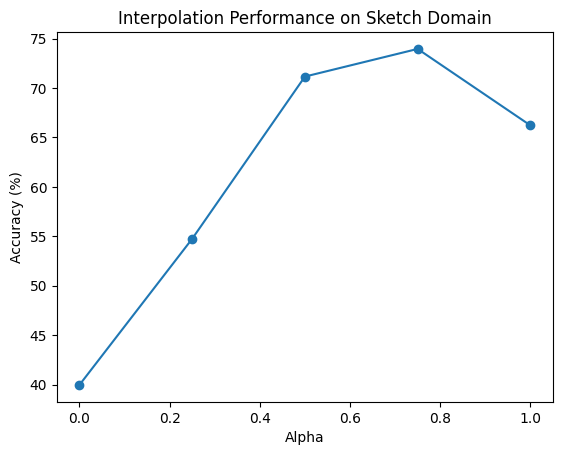

In [ ]:
import matplotlib.pyplot as plt

plt.figure()
plt.plot(alphas, results, marker='o')
plt.xlabel("Alpha")
plt.ylabel("Accuracy (%)")
plt.title("Interpolation Performance on Sketch Domain")
plt.show()
